In [77]:
import pandas as pd
import json
import numpy as np
import colorsys
import matplotlib.pyplot as plt
from descartes import PolygonPatch

from pathlib import Path

from gazebo_implementations.pattern_gen.artistic_pattern_gen import create_circle, create_triangle, create_rectangle, create_star, create_ring

In [78]:
def generate_colors(num_colors):
    # Generate equally spaced hues
    hues = [i / num_colors for i in range(num_colors)]
    
    # Set saturation and value to 1 for full saturation and brightness
    saturation = 1
    value = 1
    
    # Convert HSV to RGB
    rgb_colors = [colorsys.hsv_to_rgb(hue, saturation, value) for hue in hues]
    
    # Convert RGB to hexadecimal strings
    hex_colors = ['#%02x%02x%02x' % tuple(int(255 * c) for c in rgb) for rgb in rgb_colors]
    
    return hex_colors

# Goal positions

In [79]:
with open('gazebo_implementations/pattern_gen/patterns/5robots_patterns.json', 'r') as f:
    goals_5 = json.load(f)

with open('gazebo_implementations/pattern_gen/patterns/10robots_patterns.json', 'r') as f:
    goals_10 = json.load(f)

with open('gazebo_implementations/pattern_gen/patterns/15robots_patterns.json', 'r') as f:
    goals_15 = json.load(f)

goals = {5: goals_5, 10: goals_10, 15: goals_15}

In [82]:
np.array(goals[5]['circle'])[:,0]

array([-0.89716383, -0.53602738,  0.56251252,  0.88440705, -0.01571369])

# Polygons

In [51]:
# Create a circle
circle_center = (0, 0)
circle_radius = 1.5
circle_polygon = create_circle(circle_center, circle_radius)

# Create a triangle
triangle_vertices = [(-1.5, -1.5), (1.5, -1.5), (0, 1.5)]
triangle_polygon = create_triangle(triangle_vertices)

# Create a rectangle
rectangle_lower_left = (-1.2, -1.2)
rectangle_upper_right = (1.2, 1.2)
rectangle_polygon = create_rectangle(rectangle_lower_left, rectangle_upper_right)

# Create a star
star_polygon = create_star((0,0), 2, 1, 5)

# create a ring
ring_polygon = create_ring(circle_center, 2.2, 1)

polygons = {'circle': circle_polygon, 'triangle': triangle_polygon, 'rectangle': rectangle_polygon, 'ring': ring_polygon}

# Read file

In [95]:
def read_df(algorithm, n):
    file = f'{n}_robots.csv'
    
    df = pd.read_csv(
        Path('gazebo_implementations', 'timing', algorithm, file),
        header=[0,1],
        index_col=0
    )
    df = df.iloc[1:]

    df['Change'] = df['pattern', 'pattern'] != df['pattern', 'pattern'].shift(1)
    df['pattern_id'] = df['Change'].cumsum()
    df = df.rename_axis('timestamp')

    return df

# Plot

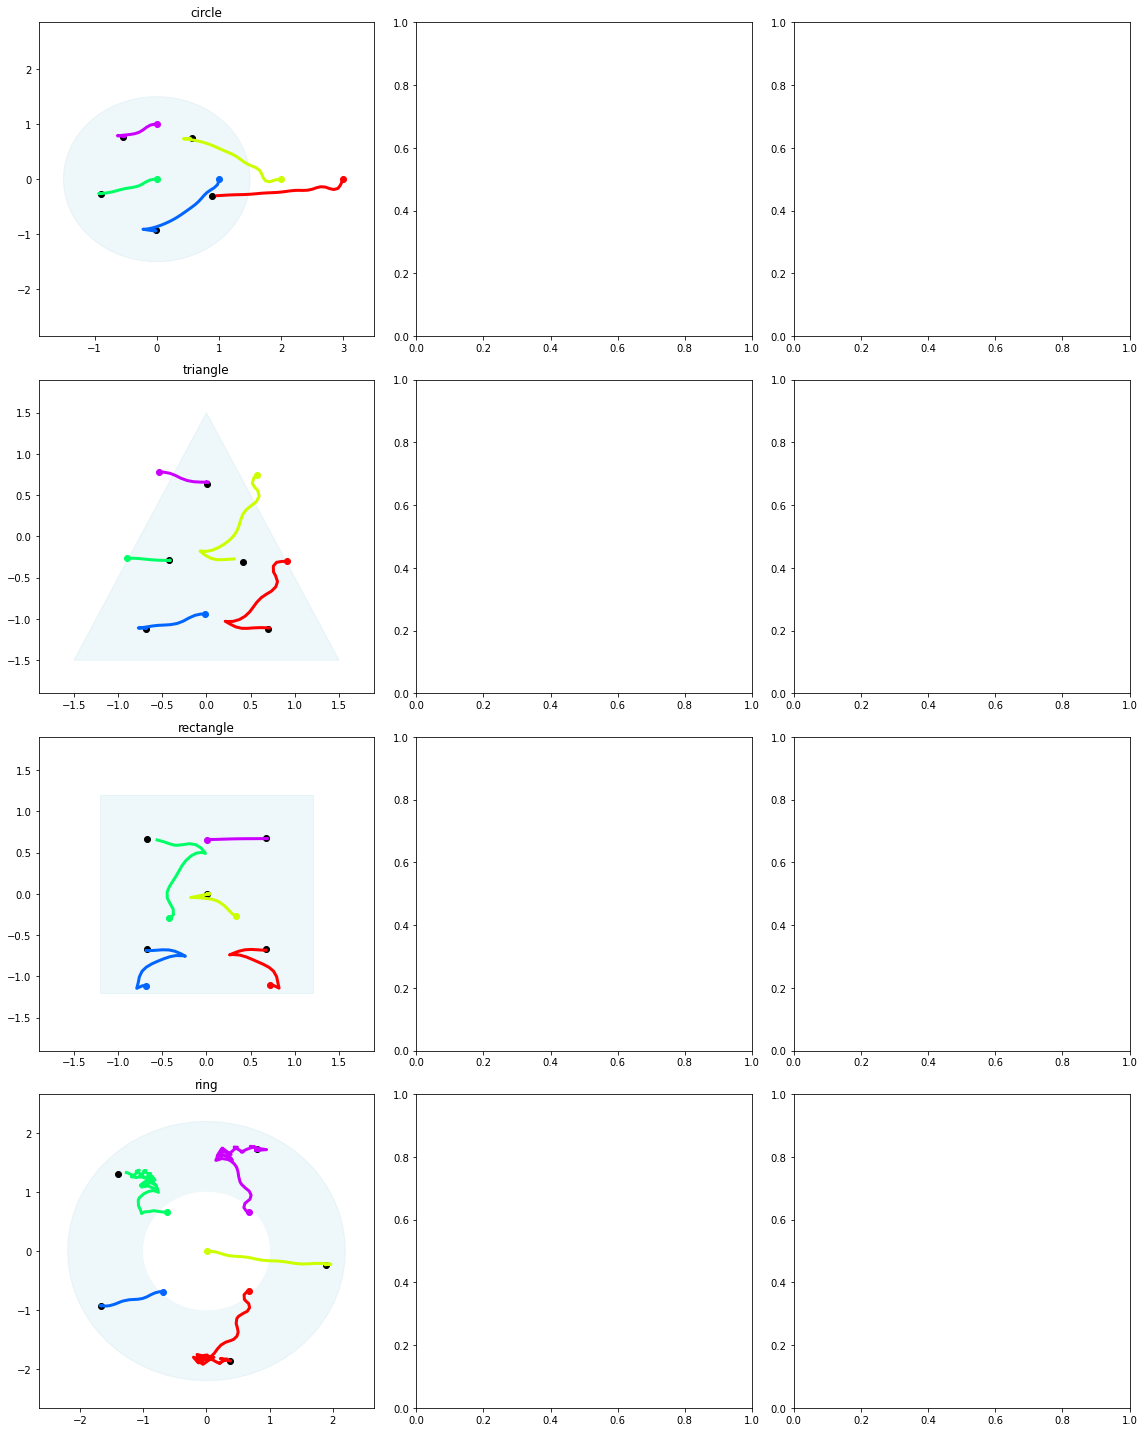

In [96]:
algorithms = ['artistic_pattern_controller',
              'target_assignement_controller',
              'mpc_controller']
algorithm = algorithms[2]

lim = 1.9
figsize = (16, num_patterns*5)
fig, axes = plt.subplots(4, 3, figsize=figsize)

for n in [1,2,3]:
    try:
        df = read_df(algorithm, n*5)
    except FileNotFoundError:
        continue

    num_patterns = 4#len(df['pattern_id'].unique()) - 1
    robot_names = set([i for i in df.columns.get_level_values(0) if i.startswith('robot')])
    colors = generate_colors(len(robot_names))

    for i in range(1, num_patterns+1):
        ax = axes[i-1][n-1]
        pattern_df = df[df['pattern_id']==i]

        try:
            pattern_name = pattern_df.iloc[0]['pattern']['pattern']
        except:
            continue
    
        # plot polygon
        polygon = polygons[pattern_name]
        x, y = polygon.exterior.xy
        ax.fill(x, y, color='lightblue', alpha=0.2)
        
        for hole in polygon.interiors:
            x, y = zip(*hole.coords)
            ax.fill(x, y, color='white')

        # plot goal positions
        goal_positions = np.array(goals[5*n][pattern_name])
        ax.scatter(
            goal_positions[:,0],
            goal_positions[:,1],
            color='black'
        )
    
        # plot paths
        for j, robot in enumerate(robot_names):
            color = colors[j]
            ax.plot(
                pattern_df[robot]['x'].values,
                pattern_df[robot]['y'].values,
                linewidth=3,
                color=color
            )
    
            # plot start positions
            ax.scatter(
                pattern_df.iloc[0][robot]['x'],
                pattern_df.iloc[0][robot]['y'],
                color=color
            )
    
        ax.set_title(pattern_name)
        ax.set_ylim([-lim, lim])
        ax.set_xlim([-lim, lim])
    
        if pattern_name == 'ring':
            ax.set_ylim([-lim*1.4, lim*1.4])
            ax.set_xlim([-lim*1.4, lim*1.4])
        if pattern_name == 'circle':
            ax.set_ylim([-lim*1.5, lim*1.5])
            ax.set_xlim([-lim, 3.5])

plt.tight_layout()

# Calculate how long each algorithm took to form a formation

In [183]:
def time_passed(algorithm, n):
    df = read_df(algorithm, n)
    df = df.reset_index()
    df = df[['timestamp', 'pattern_id', 'pattern']].droplevel('Coordinate', axis=1)
    df = df[df['pattern_id']<=4]
    pattern_names = df.groupby('pattern_id')['pattern'].first()
    start_times = df.groupby('pattern_id')['timestamp'].min()
    end_times = df.groupby('pattern_id')['timestamp'].max()
    
    time_df = pd.DataFrame({
        'pattern': pattern_names,
        'start_time': start_times,
        'end_time': end_times
    })
    
    time_df['time_passed'] = time_df['end_time'] - time_df['start_time']
    time_df = time_df[['pattern', 'time_passed']]
    return time_df.set_index('pattern')

In [184]:
n = 5

time_df = None

for algorithm in algorithms:
    df = time_passed(algorithm, n)
    df = df.rename({'time_passed': algorithm}, axis=1)
    
    if time_df is None:
        time_df = df
    else:
        time_df = time_df.join(df, how='inner')

In [186]:
time_df

,artistic_pattern_controller,target_assignement_controller,mpc_controller
pattern,,,
circle,22.724,22.632,10.984
triangle,16.017,19.321,9.329
rectangle,16.214,22.625,8.977
ring,22.141,22.632,26.345
